# quantem.data - browse, download, and view shared datasets
Pull reference scientific inputs by qualified name and immutable revision. The repository is public: browsing and downloading need no token; only uploading does.

`quantem.data` owns data transfer and metadata. The image-loading convenience below uses `quantem.widget`; native detector acquisitions should be passed to `quantem.gpu.io.load`.

## Install
This notebook uses qualified names and `revision`, which are newer than the quantem.data 0.0.1rc4 release on TestPyPI. Install quantem.widget for the image reader, then install quantem.data from this repository checkout:

```bash
python -m pip install -e .
```

The saved outputs were produced with quantem.widget 0.0.1rc41 and quantem 0.1.9. Record your source and package versions when sharing results.

## 1. See what is shared: structure
`tree()` groups datasets by type with sizes; no Hugging Face visit needed. `tree()` and `browse()` list the default branch; `DATA_REVISION` pins the calls that read data.

In [1]:
from quantem.data import tree, browse, read_meta, load

DATA_REVISION = "b30a28c295494b51139415d540819c4cbfde49b6"
tree()

bobleesj/quantem-data  (31.1 GB total, 15 datasets)

4dstem/   (8 datasets, 30.82 GB)
       18.9 MB  gold_128_npy_bin8
     3157.9 MB  gold_30mrad1.3mx04
     7081.7 MB  gold_30mrad1.3mx06
     7120.0 MB  gold_30mrad1.3mx07
     7045.0 MB  gold_30mrad1.3mx09
     4889.1 MB  gold_512
     1208.0 MB  gold_512_npy_bin4
      302.0 MB  gold_512_npy_bin8

denoise/   (1 datasets, 0.13 GB)
      126.1 MB  simulated_au_nanobeam_pg_dose1

haadf/   (4 datasets, 0.08 GB)
        8.7 MB  gold_drift_0deg
        8.7 MB  gold_drift_90deg
       33.8 MB  gold_haadf
       33.6 MB  gold_haadf_npy

widget/   (2 datasets, 0.05 GB)
       25.2 MB  ducky
       28.7 MB  gold_session


## 2. Browse visually: pick before downloading GBs
`browse()` shows a thumbnail per dataset. Thumbnails are tiny (KB); the multi-GB data is never touched.

bobleesj/quantem-data  (31.1 GB total, 15 datasets)

4dstem/   (8 datasets, 30.82 GB)
       18.9 MB  gold_128_npy_bin8
     3157.9 MB  gold_30mrad1.3mx04
     7081.7 MB  gold_30mrad1.3mx06
     7120.0 MB  gold_30mrad1.3mx07
     7045.0 MB  gold_30mrad1.3mx09
     4889.1 MB  gold_512
     1208.0 MB  gold_512_npy_bin4
      302.0 MB  gold_512_npy_bin8

denoise/   (1 datasets, 0.13 GB)
      126.1 MB  simulated_au_nanobeam_pg_dose1

haadf/   (4 datasets, 0.08 GB)
        8.7 MB  gold_drift_0deg
        8.7 MB  gold_drift_90deg
       33.8 MB  gold_haadf
       33.6 MB  gold_haadf_npy

widget/   (2 datasets, 0.05 GB)
       25.2 MB  ducky
       28.7 MB  gold_session
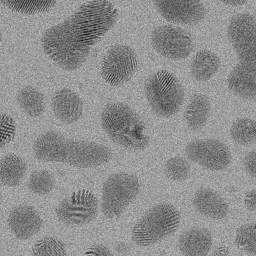
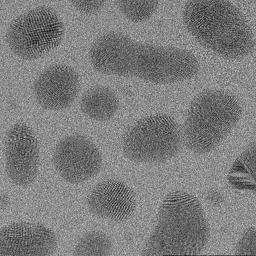
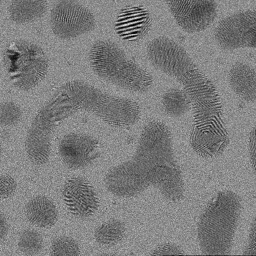
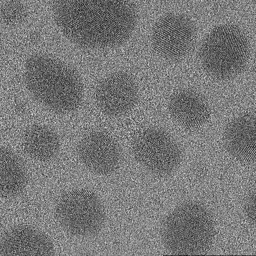
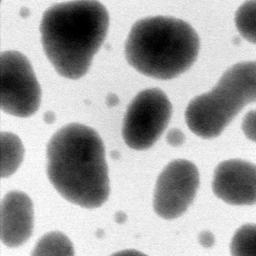
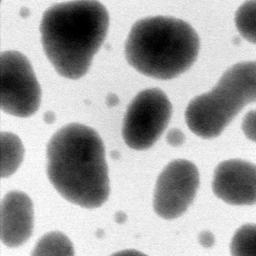
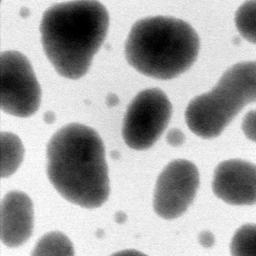
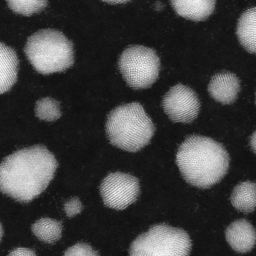
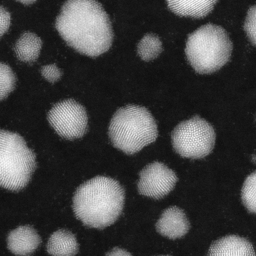
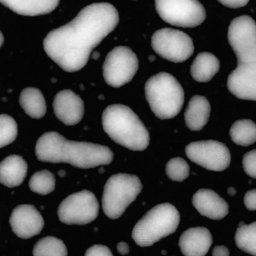
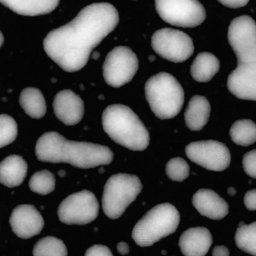

In [2]:
browse()

## 3. Check a dataset's calibration
`read_meta` returns the scan sampling / shape / units sidecar, or `None`.

In [3]:
read_meta("4dstem/gold_512_npy_bin4", revision=DATA_REVISION)

{'name': 'gold_512_npy_bin4',
 'shape': [512, 512, 48, 48],
 'dtype': 'uint16',
 'sampling': [0.5, 0.5, 1.84, 1.84],
 'units': ['A', 'A', 'mrad', 'mrad'],
 'bin_factor': {'scan': 1, 'det': 4},
 'original_shape': [512, 512, 192, 192],
 'original_sampling': [0.5, 0.5, 0.46, 0.46],
 'source': 'Arina 4D-STEM master gold_004_master.h5 (drift-pair acquisition; associated acquisition record supplies optics)',
 'purpose': 'workshop / Colab demo - full real-space, detector-only bin',
 'voltage_kV': 300,
 'camera_length_mm': 91,
 'probe_semiangle_mrad': 30,
 'mag_MX': None,
 'rotation_deg': 0.0,
 'voltage_kV_source': 'confirmed via session HAADF EMD (20260423/0072-*.emd, AccelerationVoltage)',
 'probe_semiangle_source': 'confirmed via session HAADF EMD (BeamConvergence 0.02999 rad)',
 'camera_length_source': 'confirmed via session HAADF EMD (CameraLength 0.091 m)',
 'scan_sampling_A_source': 'operator pattern from sibling 20260408 SSB calibration.json; not per-file calibrated for this 20260423 d

## 4. Download and view one shared image
The existing `load` convenience downloads this HAADF image and returns a `Dataset2d`; `.show()` plots it with Matplotlib. Pin both the scientific input and its metadata to the same revision.

For a native detector acquisition, use `quantem.data.download(qualified_id, revision=DATA_REVISION)` and pass the returned master to `quantem.gpu.io.load`. Viewer collections such as `widget/ducky` and `widget/gold_session` contain monitors or image sessions; open those with their named `quantem.widget.datasets` helpers. The revision pinned above contains these paths. quantem.widget 0.0.1rc41 requests `widget-tutorials/` paths; the `widget/` paths need a later quantem.widget.

`verbose=False` keeps the local cache path out of the saved output.

(2048, 2048) uint16


(<Figure size 400x400 with 1 Axes>,
 <Axes: title={'center': 'gold_drift_0deg'}>)

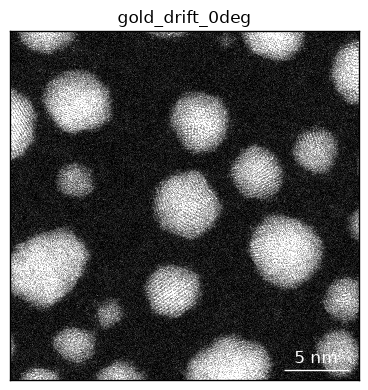

In [4]:
ds = load("haadf/gold_drift_0deg", revision=DATA_REVISION, verbose=False)
print(ds.array.shape, ds.array.dtype)
ds.show()

## Publish a dataset (owner only - needs an HF write token)
`upload` writes, so log in first (`huggingface-cli login` or `HF_TOKEN`). Attach calibration with `meta=`. Not run here (it mutates the repo):
```python
from quantem.data import upload
upload('my_scan.h5', name='gold_run42', folder='4dstem',
       meta={'voltage_kV': 300, 'scan_sampling_A': 0.2})
```
Same from the shell:
```bash
quantem-data list                       # or: tree / status
quantem-data meta gold_512_npy_bin4
quantem-data download gold_drift_0deg
quantem-data upload my_scan.h5 --folder 4dstem --name gold_run42 --meta cal.json
```